# Assignment 4. Contingency Table

1. Consider two nominal features in your dataset. At most one may be taken directly from the existing nominal features; the other must be developed by you.

2. Build a contingency table for these features. Compute conditional frequency and Quetelet index tables. Comment on the most strongly associated categories.

3. Compute and compare the average Quetelet index and Pearson’s chi-squared.

4. Determine the numbers of observations sufficient to detect an association at the **95%** and **99% confidence levels**. Consult statistical tables online if necessary.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('spotify_pop_1000.csv')
display(df.head())
print(f'\nDataset shape: {df.shape}')

,track_name,artists,popularity,duration_ms,explicit,danceability,energy,loudness,valence,tempo,acousticness
0,Blinding Lights,The Weeknd,91,200040,False,0.514,0.730,-5.934,0.334,171.005,0.00146
1,Mann Mera,Gajendra Verma,74,200120,False,0.535,0.765,-7.862,0.373,191.827,0.05400
2,Summer High,AP Dhillon,83,177391,False,0.860,0.541,-6.510,0.952,114.984,0.16500
3,Under The Influence,Chris Brown,96,184613,True,0.733,0.690,-5.529,0.310,116.992,0.06350
4,Starboy,The Weeknd;Daft Punk,90,230453,True,0.679,0.587,-7.015,0.486,186.003,0.14100



Dataset shape: (1000, 11)


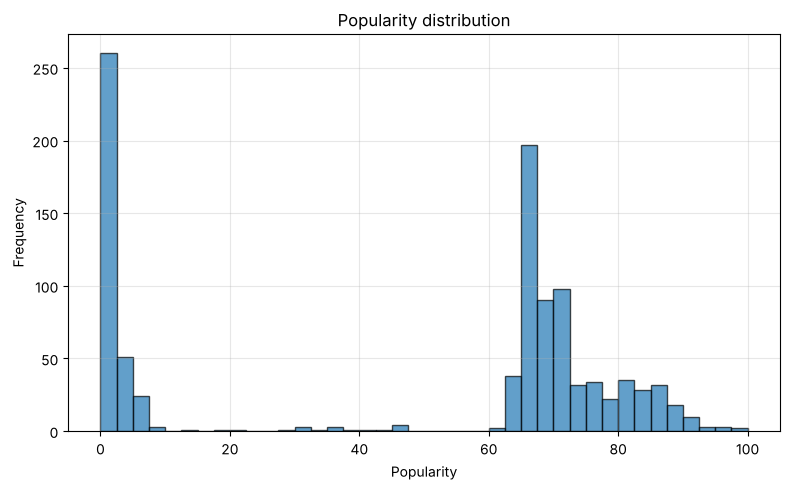

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['popularity'], bins=40, edgecolor='black', alpha=0.7)
plt.xlabel('Popularity')
plt.ylabel('Frequency')
plt.title('Popularity distribution')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

print('Popularity distribution:')
print(f'Minimum: {df["popularity"].min():.2f}')
print(f'Maximum: {df["popularity"].max():.2f}')
print(f'Mean: {df["popularity"].mean():.2f}')
print(f'Median: {df["popularity"].median():.2f}')
print('Quartiles:')
display(df['popularity'].quantile([0.25, 0.5, 0.75]))

Popularity distribution:
Minimum: 0.00
Maximum: 100.00
Mean: 47.58
Median: 66.00
Quartiles:


0.25     2.0
0.50    66.0
0.75    71.0
Name: popularity, dtype: float64

In [ ]:
x1 = pd.cut(
    df['popularity'],
    bins=[-1, 19, 69, 100],
    labels=['low', 'medium', 'high'])

print('x1 (popularity categories):')
print(x1.value_counts(sort=False))
print(f'Type: {x1.dtype}')

x1 (popularity categories):
popularity
low       340
medium    343
high      317
Name: count, dtype: int64
Type: category


**Two nominal features.**

- **x2 = explicit** is the existing nominal feature of the dataset: whether a track is marked as containing explicit lyrics (926 non-explicit, 74 explicit).
- **x1 = popularity level** is the feature I developed from the quantitative `popularity` score (0–100): **low** (0–19), **medium** (20–69) and **high** (70–100). It gives three categories of similar size: 340, 343 and 317 tracks.

The cut points are round numbers. I did not use the mean-based categories of the insurance example, because popularity is strongly bimodal: 338 tracks have a score below 20 (182 of them exactly 0), and most of the others lie between 60 and 89. Cut points based on the mean (47.6) would produce categories with almost no observations, which makes the chi-squared test unreliable. With the categories above, all expected counts in the table are at least 23, so the chi-squared approximation is valid.

The question behind the table: *are explicit tracks distributed differently over popularity levels than other tracks?*

In [ ]:
x2 = df['explicit']
print('x2 (explicit):')
display(x2.value_counts())

x2 (explicit):


explicit
False    926
True      74
Name: count, dtype: int64

## Contingency Table

In [ ]:
contingency_x1_x2 = pd.crosstab(x1, x2)
print('Contingency table x1/x2 (popularity/explicit):')
display(contingency_x1_x2)

Contingency table x1/x2 (popularity/explicit):


explicit,False,True
popularity,,
low,315,25
medium,338,5
high,273,44


## Conditional Probabilities P(x1|x2)

In [ ]:
cond_prob_x1_x2 = contingency_x1_x2 / contingency_x1_x2.sum(axis=0)
print('Conditional probabilities P(x1|x2):')
display(cond_prob_x1_x2.round(4))

Conditional probabilities P(x1|x2):


explicit,False,True
popularity,,
low,0.3402,0.3378
medium,0.3650,0.0676
high,0.2948,0.5946


## Quetelet Coefficients

In [ ]:
marginal_x1 = contingency_x1_x2.sum(axis=1) / contingency_x1_x2.sum().sum()
print('Marginal probabilities x1:')
display(marginal_x1.round(4))

Marginal probabilities x1:


popularity
low       0.340
medium    0.343
high      0.317
dtype: float64

In [ ]:
ketle_x1_x2 = cond_prob_x1_x2.div(marginal_x1, axis=0) - 1
print('Quetelet coefficients for x1/x2:')
display(ketle_x1_x2.round(4))

Quetelet coefficients for x1/x2:


explicit,False,True
popularity,,
low,0.0005,-0.0064
medium,0.0642,-0.8030
high,-0.0700,0.8757


### Most Strongly Associated Categories

The Quetelet coefficient compares a conditional probability with the overall proportion of a category. A positive value indicates a higher frequency, a negative value indicates a lower frequency, and zero means that the frequencies coincide. A value of −1 means that the cell contains no observations.

**Popularity / explicit.** The largest positive coefficient, **0.8757**, corresponds to **high popularity and explicit tracks**. High popularity occurs among 59.46% of explicit tracks, compared with 31.70% overall — about 1.88 times as often. Among non-explicit tracks this proportion is 29.48%.

The largest negative coefficient, **−0.8030**, corresponds to **medium popularity and explicit tracks**: only 6.76% of explicit tracks (5 out of 74) have medium popularity, against 34.30% overall, which is about 5 times less often. Low popularity has a coefficient near zero for both groups (−0.0064 for explicit, 0.0005 for non-explicit), so explicit tracks are as often unpopular as the others: the difference is concentrated in the high and medium levels. In other words, explicit tracks are rarely "medium" and are over-represented among the hits.

The coefficients for non-explicit tracks are small (between −0.070 and 0.064), because this group is 92.6% of the data and therefore close to the overall proportions.

The reverse conditional probability has a different meaning: among tracks with high popularity, 44 out of 317 are explicit, or 13.88%, compared with 7.40% explicit tracks overall. This should not be confused with the proportion of high popularity among explicit tracks (59.46%).

Note that the association says nothing about causes: it only shows that explicit tracks in this sample are more often highly popular.

## Average Quetelet Index in the Contingency Table

Use a weighted average: multiply each cell's Quetelet coefficient by the proportion of observations in that cell and sum the results. Do not take absolute values. This is an average over observations, not an unweighted average over cells.

In [ ]:
n = contingency_x1_x2.to_numpy().sum()
mean_ketle_x1_x2 = ((contingency_x1_x2 / n) * ketle_x1_x2).to_numpy().sum()
print(f'Average Quetelet index (popularity / explicit): {mean_ketle_x1_x2:.4f}')

Average Quetelet index (popularity / explicit): 0.0371


The average Quetelet index is 0.0371. Its value indicates the average change of the probability of a feature category when the category of the other feature becomes known.

This is a small value: on average, knowing whether a track is explicit changes the probability of its popularity level by only about 3.7%. The reason is that explicit tracks are only 74 of 1000 observations, so the large coefficients (0.8757 and −0.8030) apply to few observations and are weighted down. The association is real but concentrated in a small group. (The square root of χ²/n, 0.193, is Cramér's V for this table: a weak to moderate association.)

## Chi-Squared and Comparison with the Average Quetelet Index

In [ ]:
from scipy.stats import chi2_contingency

chi2_x1_x2, p_value_x1_x2, dof_x1_x2, expected_x1_x2 = chi2_contingency(contingency_x1_x2)
chi2_norm_x1_x2 = chi2_x1_x2 / n

print('Popularity / explicit:')
print(f'χ² = {chi2_x1_x2:.2f}')
print(f'χ²/n = {chi2_norm_x1_x2:.4f}')
print(f'Degrees of freedom = {dof_x1_x2}')
print(f'Average Quetelet = {mean_ketle_x1_x2:.4f}')

Popularity / explicit:
χ² = 37.10
χ²/n = 0.0371
Degrees of freedom = 2
Average Quetelet = 0.0371


They coincide as expected: the average Quetelet index equals χ²/n (37.10 / 1000 = 0.0371), so χ² = n × (average Quetelet index).

The two numbers serve different purposes. The **average Quetelet index** (0.0371) measures the *strength* of the association and does not depend on the number of observations. The **Pearson χ²** (37.10) is the same quantity multiplied by n, so it grows with the sample size and is used to test *whether the association is statistically significant*: with 2 degrees of freedom the critical value at 95% is 5.99 and at 99% is 9.21, and the observed 37.10 is far above both (p ≈ 8.8·10⁻⁹). So the association is statistically very significant although its strength is modest.

Note on independence of observations: some songs appear more than once in the file (233 repeat listings on different albums), while the χ² test assumes independent observations. As a check, with only the 767 unique songs (same name and artist counted once) the result is χ² = 33.28, χ²/n = 0.0434, p ≈ 6·10⁻⁸, so the conclusion does not change.

## Sample Sizes for Detecting an Association at the 95% and 99% Levels

First, calculate the required sample-size boundary:

$$
N_{\mathrm{req}} = N_{\mathrm{curr}}\cdot
\frac{\chi^2_{\mathrm{critical}}}{\chi^2_{\mathrm{observed}}}.
$$

Variables in the formula:

- **N_curr** — the number of observations in the contingency table: the sum of all its cells.
- **chi2_observed** — the observed χ² statistic calculated from the table using `chi2_contingency`.
- **dof** — degrees of freedom: (number of rows − 1) × (number of columns − 1).
- **chi2_critical** — the critical value of the chi-squared distribution, obtained using `chi2.ppf(0.95, dof)` for 95% and `chi2.ppf(0.99, dof)` for 99%. This is equivalent to consulting a statistical table; it is not estimated from the original expense values.

Substitute the values into the formula and select the smallest integer **strictly above** the boundary: `floor(N_req) + 1`. The test statistic will then exceed the critical value.

The calculation assumes unchanged observed proportions: χ² grows proportionally to the sample size. This is a formal threshold based on the asymptotic chi-squared approximation, not a power calculation or a guarantee for a new random sample.

In [ ]:
from scipy.stats import chi2, chi2_contingency

print("Formula: N_req = N_curr * chi2_critical / chi2_observed")

table = contingency_x1_x2
print('\nPopularity / explicit')

N_curr = table.to_numpy().sum()
print(f"1. N_curr = sum of all cells = {N_curr}")

# Calculate the observed chi-squared statistic.
chi2_observed, p_value, _, expected = chi2_contingency(table, correction=False)
print(f"2. chi2_observed = chi2_contingency(table)[0] = {chi2_observed:.6f}")

# Calculate degrees of freedom from the table dimensions.
n_rows, n_cols = table.shape
dof = (n_rows - 1) * (n_cols - 1)
print(f"3. dof = ({n_rows} - 1) * ({n_cols} - 1) = {dof}")

# Find critical values for both confidence levels.
crit_95 = chi2.ppf(0.95, dof)
crit_99 = chi2.ppf(0.99, dof)
print(f"4. crit_95 = chi2.ppf(0.95, {dof}) = {crit_95:.6f}")
print(f"   crit_99 = chi2.ppf(0.99, {dof}) = {crit_99:.6f}")

# Substitute the values into the formula.
N_req_95 = N_curr * crit_95 / chi2_observed
N_req_99 = N_curr * crit_99 / chi2_observed
print(f"5. For 95%: {N_curr} * {crit_95:.6f} / {chi2_observed:.6f} = {N_req_95:.4f}")
print(f"   For 99%: {N_curr} * {crit_99:.6f} / {chi2_observed:.6f} = {N_req_99:.4f}")


N_min_95 = int(np.floor(N_req_95)) + 1
N_min_99 = int(np.floor(N_req_99)) + 1
print(f"6. Minimum integer sample size: 95% — {N_min_95}, 99% — {N_min_99}")

Formula: N_req = N_curr * chi2_critical / chi2_observed

Popularity / explicit
1. N_curr = sum of all cells = 1000
2. chi2_observed = chi2_contingency(table)[0] = 37.101995
3. dof = (3 - 1) * (2 - 1) = 2
4. crit_95 = chi2.ppf(0.95, 2) = 5.991465
   crit_99 = chi2.ppf(0.99, 2) = 9.210340
5. For 95%: 1000 * 5.991465 / 37.101995 = 161.4863
   For 99%: 1000 * 9.210340 / 37.101995 = 248.2438
6. Minimum integer sample size: 95% — 162, 99% — 249


This shows that the hypothesis of independence will be rejected at the 95% confidence level when the number of observations is **162 or more** (the boundary is 161.49), and at the 99% confidence level when it is **249 or more** (the boundary is 248.24), provided that the proportions in the table stay the same.

The present sample (1000 tracks) is far above both numbers, which agrees with the very small p-value found above. Only about one sixth to one quarter of the data would be enough to detect this association.

This is a formal threshold. With about 162 observations and the same proportions there would be only about 12 explicit tracks, with expected counts of about 4 in each popularity level, which is below the usual rule of 5, so the chi-squared approximation would be rough there. At 249 observations the expected counts are about 6, which is acceptable.